# Lab 18: How to choose an agent design

**Notebook 1 of 2: one agent or five, on a book club's shortlist**

## Goal

Decide when a second agent is worth what it costs, by looking at what the agent that writes the answer has to read. A
book club has five books on its shortlist and asks which one to read next. One agent can read all five blurbs and
answer. Or our code can start five small agents at the same time, each reading one blurb and returning one line, and
give the five lines to an agent that writes the answer. Both designs pick the same book. The difference is in what the
answering agent read before it wrote: five whole blurbs, or five lines. The split pays for that with more model
requests and more tokens in total. We then build and draw the three ways to connect two agents (as a tool, with a
handoff, in our own code), and finish with plain code that answers the club's chat commands with no model at all.

## What you will learn

- How to see what an agent read before it answered: the last model request of a run and its input tokens.
- How to run several agents at the same time from our own code with `asyncio.gather`, and pass their one-line
  results to another agent.
- How to compare two designs on one question: the answer, the model requests, the tokens in total, and the tokens
  of the request that wrote the answer.
- How to tell the three ways of connecting two agents apart (as a tool, with a handoff, in our code) from their
  drawings, and say who decides the next step in each.
- How to answer a request in code, with no model call, when a label on it already says what to do.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import asyncio
import os
import time
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Two settings go to every agent in this notebook. The client waits at most 60 seconds for a reply (the default is ten
minutes), so a stuck request fails quickly. `SETTINGS` passes the reasoning effort from `models.env` to every model
request; the SDK does not read that file itself.

In [2]:
from openai import AsyncOpenAI
from openai.types.shared import Reasoning
from agents import Agent, ModelSettings, Runner, function_tool, set_default_openai_client

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))
SETTINGS = ModelSettings(reasoning=Reasoning(effort=EFFORT))

![Three designs side by side. One agent calls read_blurb five times and writes the answer after reading five whole blurbs. Our code starts five reader agents at the same time, each reading one blurb; their five one-line notes go to a chooser agent with no tools, which writes the answer after reading five lines. In the hybrid, our code checks whether a message is a command: /next and /pages are answered by our code with no model call, and free text goes to an agent.](resources/lab18_designs.png)

The picture shows the three designs this notebook runs, one part each. Dark boxes are where a model decides what
happens next; green boxes are where our code decides. White boxes are the rest: the question or message, the
answers, and the five readers, agents that each read their own blurb and decide nothing about what runs next.

---

## Part A: Read the club's wishes and the five blurbs

A book club asks for help choosing its next book from a shortlist of five. Before any agent runs, we read what the
club wants and what the agent will have to read.

The club's wishes are one paragraph, which every agent in this notebook gets in its instructions. The blurbs are in
`book_club/`, one Markdown file per book: five made-up books, written for this lab, about 300 words each, the kind of
text a publisher prints on the back cover.

In [3]:
CLUB = ("Our book club meets in three weeks. What we want from the next book: no more than 350 pages; short "
        "chapters, because most of us read on the bus; a happy ending, because last month's book made half of us "
        "cry; and a book that stands on its own, because we have not read anything else by these authors.")

# Each file starts with a line "# Title"; BOOKS maps the title to the whole text of the blurb
BOOKS = {}
for path in sorted((ROOT / "18_Agent_Designs" / "book_club").glob("*.md")):
    text = path.read_text(encoding="utf-8")
    title = text.splitlines()[0].removeprefix("# ")
    BOOKS[title] = text

for title, text in BOOKS.items():
    print(f"{title:27} {len(text.split())} words")

A Short History of Clouds   274 words
Return to Harbour Street    261 words
Salt and Saffron            285 words
The Lighthouse Bakery       286 words
The Night Ferry             297 words


Five books, 261 to 297 words each. `BOOKS` is a dictionary: the key is the title from the file's first line, the
value is the whole blurb. One blurb in full:

In [4]:
print(BOOKS["Salt and Saffron"])

# Salt and Saffron

A memoir with recipes by Leila Haddad. Paperback, 236 pages, 24 short chapters.

Every summer of her childhood, Leila Haddad was sent to stay with her grandmother in a stone house above the sea.
Her grandmother did not believe in measuring cups. She cooked by smell, by the colour of onions in the pan, and by
the sound rice makes when it is ready. This book is Leila's attempt, thirty years later, to write those dishes down
before they are lost.

Each short chapter is one dish and one memory: the lentil soup that ended an argument between two neighbours, the
saffron rice made for a wedding that almost did not happen, the bread baked at four in the morning on the day the
power failed. The recipes are at the end of each chapter, written the way her grandmother would have said them,
with a modern version for cooks who do need a measuring cup.

The writing is warm and funny, full of the noise of a big family kitchen. But this is also a book about losing
someone. The final

Read it the way the club would. 236 pages and short chapters fit, and the book stands on its own. Then the third
paragraph: the last chapters were written after the grandmother's death, and many readers cried at the ending. The
book fails one wish, and only a reader who gets to the third paragraph finds that out. Every blurb on the shortlist
works like this: to judge a book, an agent has to read the whole blurb.

### The tool that reads one blurb

Both designs read the blurbs through the same tool. `read_blurb(title)` returns the blurb of a book on the shortlist,
or a sentence saying there is no such book: a sentence, not an empty result, so the model reads a clear "no match".
`function_tool` turns the function into a tool from its name, its docstring and its type hints.

In [5]:
def read_blurb(title: str) -> str:
    """Read the publisher's blurb of one book on the club's shortlist.

    Args:
        title: The book's title, exactly as it is on the shortlist.
    """
    for known_title, text in BOOKS.items():
        if known_title.lower() == title.strip().lower():
            return text
    return f"There is no book called {title!r} on the shortlist."


READ_BLURB = function_tool(read_blurb)

print(read_blurb("The Night Ferry")[:120], "...")
print(read_blurb("The Day Ferry"))

# The Night Ferry

A thriller by Idris Calloway. Paperback, 412 pages, 31 chapters.

Nadia Farouk has worked the night s ...
There is no book called 'The Day Ferry' on the shortlist.


A known title returns its blurb (here the first 120 characters); an unknown one returns the sentence. The title is
matched without regard to capitals, because the model writes the title as an argument and may not copy its capitals
exactly.

**Checkpoint A.** Five books in `BOOKS`, about 300 words each. *Salt and Saffron* is 236 pages, and its third
paragraph says the ending made readers cry. `read_blurb` returns a blurb for a known title and a sentence for an
unknown one.

---

## Part B: Let one agent read all five blurbs and answer

The simplest design comes first, and every other design is compared with it: one agent with the club's wishes in its
instructions and `read_blurb` as its tool.

In [6]:
helper = Agent(
    name="Book club helper",
    instructions=("You help a book club choose its next book. Read the blurbs with your tool before you answer. "
                  + CLUB + " Answer in a few sentences."),
    model=MODEL,
    tools=[READ_BLURB],
    model_settings=SETTINGS,
)

QUESTION = "Which of these five books should our book club read next? " + "; ".join(BOOKS) + "."
print(QUESTION)

Which of these five books should our book club read next? A Short History of Clouds; Return to Harbour Street; Salt and Saffron; The Lighthouse Bakery; The Night Ferry.


`"; ".join(BOOKS)` joins the dictionary's keys, the five titles, so the question names every book on the shortlist.

Before you run the next cell: how many times will the agent call `read_blurb`, and how many model requests will the
run take?

In [7]:
result = await Runner.run(helper, QUESTION)

print(result.final_output)

**The Lighthouse Bakery** is the best fit: it’s 288 pages, has short chapters suited to bus reading, ends joyfully, and stands alone. **Return to Harbour Street** also has short chapters and a happy ending, but it’s a sequel; the other options either have long chapters, a sad ending, or exceed 350 pages.


The agent picked *The Lighthouse Bakery*: 288 pages, short chapters, a joyful ending, and no other book needed. It also said which wish each other book misses: *Return to Harbour Street* is a sequel, and the rest have long chapters, a sad ending or too many pages. That matches the blurbs: only *The Lighthouse Bakery* meets all four wishes.

### What the agent read before it answered

`result.raw_responses` has one entry per model request. For each one we print its input tokens (how much the model
read) and what it sent back: the names of the tools it asked for, or `message` when it wrote the answer.

In [8]:
for number, response in enumerate(result.raw_responses, start=1):
    asked = [getattr(part, "name", part.type) for part in response.output]
    print(f"request {number}: {response.usage.input_tokens:5} input tokens -> {asked}")

request 1:   212 input tokens -> ['read_blurb', 'read_blurb', 'read_blurb', 'read_blurb', 'read_blurb']
request 2:  2083 input tokens -> ['message']


Two requests:

1. The first read 212 tokens (the instructions and the question) and asked for `read_blurb` five times in one reply. The five blurbs do not depend on each other, so the model asked for all of them at once, and the SDK ran the five calls before the next request.
2. The second read 2,083 tokens, ten times as many, because it carried the question, the five calls and the five blurbs. It wrote the answer.

We give the last request a name, because the rest of the lab compares it across designs. The **answering request**
is the model request that writes the answer, the last one of a run. Its input tokens measure everything the model had
to read just before it answered: the question, every tool call and every tool result so far, and the instructions.

To see that input itself, `result.to_input_list()` returns the run's conversation as a list of items, in the form
the SDK sends to the model. The last item is the answer, so `[:-1]` leaves what the answering request read (the
instructions travel beside this list, in a field of their own). A user message has no `type` key, so the cell reads
each item's kind with `.get("type", "message")`.

In [9]:
for item in result.to_input_list()[:-1]:
    kind = item.get("type", "message")
    if kind == "function_call":
        print("tool call   |", item["name"], item["arguments"])
    elif kind == "function_call_output":
        print("tool result |", item["output"].splitlines()[0], f"({len(item['output'].split())} words)")
    else:
        print("question    |", item["content"][:70], "...")

question    | Which of these five books should our book club read next? A Short Hist ...
tool call   | read_blurb {"title":"A Short History of Clouds"}
tool call   | read_blurb {"title":"Return to Harbour Street"}
tool call   | read_blurb {"title":"Salt and Saffron"}
tool call   | read_blurb {"title":"The Lighthouse Bakery"}
tool call   | read_blurb {"title":"The Night Ferry"}
tool result | # A Short History of Clouds (274 words)
tool result | # Return to Harbour Street (261 words)
tool result | # Salt and Saffron (285 words)
tool result | # The Lighthouse Bakery (286 words)
tool result | # The Night Ferry (297 words)


The answering request read the question, five tool calls and five whole blurbs, about 1,400 words. It needed them:
the blurbs are where the page counts, the chapters and the endings are. For five blurbs that is
2,083 tokens, which a model reads easily. The cost of this design shows when the reading grows: fifty books, or a
chapter of each instead of a blurb, and the answering request carries all of it.

**Checkpoint B.** One agent, 2 model requests: the first asks for `read_blurb` five times, the second writes
the answer. The answering request read the question, five calls and five blurbs (2,083 input tokens in our run).

---

## Part C: Split the reading across five sub-agents that run at the same time

In Part B the agent that wrote a few sentences had first read five whole blurbs. A different design keeps that
reading away from it.

A **sub-agent** is an agent started for one part of a job: it does its own reading and returns only its result. Here
a **reader** agent reads one blurb and replies with one line: the title, whether the book fits, and why. Our code
starts one reader per book, all at the same time, and a **chooser** agent, with no tools, writes the answer from the
five lines.

### One reader on one book

In [10]:
reader = Agent(
    name="Blurb reader",
    instructions=("You read the blurb of one book for a book club. " + CLUB + " Read the blurb with your tool, "
                  "then reply with one line: the title, whether it fits, and why."),
    model=MODEL,
    tools=[READ_BLURB],
    model_settings=SETTINGS,
)

started = time.perf_counter()
one_reader = await Runner.run(reader, "Read 'Salt and Saffron' and tell us whether it fits.")
print(one_reader.final_output)
print(f"requests: {one_reader.context_wrapper.usage.requests} | {time.perf_counter() - started:.1f} seconds")

Salt and Saffron — doesn’t fit: it’s 236 pages with short chapters and stands alone, but its ending is sad, not happy.
requests: 2 | 2.5 seconds


One line: *Salt and Saffron* does not fit, because its ending is sad. It took 2 requests, one to ask for the blurb and one to write the line, in 2.5 seconds. The blurb stayed inside the reader's run: whoever reads its answer reads one line. The count of 2 requests comes from `one_reader.context_wrapper.usage`, which adds up the requests and tokens of the whole run.

### Five readers at the same time

`Runner.run(...)` written without `await` does not run anything yet: it makes a **coroutine**, a run waiting to be
started. `asyncio.gather(...)` starts every coroutine it is given, waits until the last one has finished, and returns
their results in the order it got them. The `*` passes the list of five coroutines as five separate arguments.

`with trace("Book club shortlist"):` puts the five runs under one trace with that name. A trace is the SDK's record
of a run (each model request and tool call), sent to the Traces page of the OpenAI account that owns the key.

In [11]:
from agents import trace

started = time.perf_counter()
with trace("Book club shortlist"):
    reader_runs = await asyncio.gather(
        *[Runner.run(reader, f"Read '{title}' and tell us whether it fits.") for title in BOOKS])
print(f"five readers: {time.perf_counter() - started:.1f} seconds")

for run in reader_runs:
    print("-", run.final_output)

five readers: 3.0 seconds
- A Short History of Clouds — doesn’t quite fit: it’s 224 pages, standalone, and ends hopefully, but its six dense, roughly 40-page chapters aren’t suited to short bus-ride reading.
- *Return to Harbour Street* — Doesn’t fit: it’s 304 pages with short chapters and a happy ending, but it’s a sequel that depends on having read *Harbour Street*.
- Salt and Saffron — Doesn’t fit: it’s 236 pages with short chapters and stands alone, but the ending is sad, not happy.
- The Lighthouse Bakery — fits: it’s 288 pages, has 40 short chapters, ends joyfully and hopefully, and stands alone.
- **The Night Ferry — No:** it’s 412 pages, has long chapters, and its blurb doesn’t confirm a happy ending or that it stands alone.


Five lines, one per book, in the order of the titles in `BOOKS`, because `gather` keeps the order of its arguments. Each line names the wish its book misses, and only *The Lighthouse Bakery* fits. The five runs together took 3.0 seconds, about the time of the single reader above (2.5 seconds), because they ran at the same time: a model request spends most of its time waiting for the reply, and the five waits overlapped.

### The chooser reads five lines

The chooser has the club's wishes in its instructions and no tools. Its input is the question and the five lines,
which we print in full before it runs: this is all it will read.

In [12]:
chooser = Agent(
    name="Book club chooser",
    instructions=("You help a book club choose its next book. " + CLUB + " Answer from the notes you are given. "
                  "Answer in a few sentences."),
    model=MODEL,
    model_settings=SETTINGS,
)

notes = "\n".join(run.final_output for run in reader_runs)
chooser_input = QUESTION + "\n\nNotes from the readers:\n" + notes
print(chooser_input)

Which of these five books should our book club read next? A Short History of Clouds; Return to Harbour Street; Salt and Saffron; The Lighthouse Bakery; The Night Ferry.

Notes from the readers:
A Short History of Clouds — doesn’t quite fit: it’s 224 pages, standalone, and ends hopefully, but its six dense, roughly 40-page chapters aren’t suited to short bus-ride reading.
*Return to Harbour Street* — Doesn’t fit: it’s 304 pages with short chapters and a happy ending, but it’s a sequel that depends on having read *Harbour Street*.
Salt and Saffron — Doesn’t fit: it’s 236 pages with short chapters and stands alone, but the ending is sad, not happy.
The Lighthouse Bakery — fits: it’s 288 pages, has 40 short chapters, ends joyfully and hopefully, and stands alone.
**The Night Ferry — No:** it’s 412 pages, has long chapters, and its blurb doesn’t confirm a happy ending or that it stands alone.


In [13]:
chosen = await Runner.run(chooser, chooser_input)

print(chosen.final_output)
print()
print("answering request:", chosen.raw_responses[-1].usage.input_tokens, "input tokens")

Read *The Lighthouse Bakery*. It’s 288 pages, has short chapters for bus rides, ends joyfully and hopefully, and stands alone.

answering request: 320 input tokens


The chooser picked *The Lighthouse Bakery*, as the one agent did in Part B. Its answering request read 320 input tokens: the instructions, the question and five lines. In Part B the answering request read 2,083.

### What the split cost

One cell puts the two designs side by side. The split's numbers add up all six runs: five readers and the chooser.

The numbers come from two objects. `run.context_wrapper.usage` adds up every model request of a run: `.requests`
counts them, and `.input_tokens` sums what they read. `run.raw_responses[-1].usage` holds the counts of the last request alone, the answering request.

In [14]:
split_runs = [*reader_runs, chosen]

print("one agent:              requests", result.context_wrapper.usage.requests,
      "| input tokens in total", result.context_wrapper.usage.input_tokens,
      "| answering request", result.raw_responses[-1].usage.input_tokens)
print("five readers + chooser: requests", sum(run.context_wrapper.usage.requests for run in split_runs),
      "| input tokens in total", sum(run.context_wrapper.usage.input_tokens for run in split_runs),
      "| answering request", chosen.raw_responses[-1].usage.input_tokens)

one agent:              requests 2 | input tokens in total 2295 | answering request 2083
five readers + chooser: requests 11 | input tokens in total 4189 | answering request 320


- **Answering request:** 320 tokens against 2,083, about a sixth. This is what the split buys.
- **Requests:** 11 against 2: five readers of 2 requests each, and the chooser's one.
- **Input tokens in total:** 4,189 against 2,295 (one agent's two requests, 212 + 2,083), nearly twice as many. Every reader sends the instructions and the club's wishes on both of its requests and its blurb on the second, so the split still reads all five blurbs, only in five places.

**Key lesson:** the split did not make the answer better; both designs picked the same book. It moved the reading away
from the agent that answers, and paid for that with more requests and more tokens. That is worth it when the reading
is large (whole chapters instead of blurbs, fifty books instead of five), when the answering agent should stay small
or run on a stronger model that costs more per token, or when the parts are slow and gain from running at the same
time.

**Important:** the chooser can use only what the five lines say. A question the lines do not cover, such as which
book has recipes in it, is out of its reach; the Challenge tries one.

### The run on the Traces page

The five reader runs were recorded as one trace, *Book club shortlist*, on the Traces page of the OpenAI account that
owns the key ([platform.openai.com/traces](https://platform.openai.com/traces)). Open it and the five runs sit under
the trace's name, each with its own model requests and its `read_blurb` call, overlapping on the timeline because
they ran at the same time. The other runs of this notebook have a trace each, named *Agent workflow*.

*Screenshot to add: the Traces page with the Book club shortlist trace open.*

**Checkpoint C.** One reader: one line, 2 requests. Five readers: five lines, each judging one book, in about the
time of one reader. The chooser reads the question and five lines (320 input tokens in our run, against
2,083 for one agent), and picks the same book as Part B. The split costs more: 11 requests against
2, and more input tokens in total.

---

## Part D: Connect two agents as a tool, with a handoff, and in our code

In Part C our code decided what ran next: first the readers, then the chooser. The Agents SDK offers two more ways to
connect two agents, and in both a model decides. Lab 07's second notebook runs both on the Chinook support desk. Here
we build them from the book club's agents and draw them with `draw_graph`, without running them: the drawing shows
what each design lets happen. `draw_graph` draws an agent object with its tools and its handoffs; in each drawing,
`__start__` marks where a run begins and `__end__` where the reply leaves. (`draw_graph` needs the Graphviz program;
see Troubleshooting if the cell fails.)

### The reader as a tool of the chooser

`reader.as_tool(...)` wraps the whole reader agent as a tool. When the chooser's model calls it, the SDK runs the
reader on the input the chooser wrote and returns the reader's one line as the tool's result.

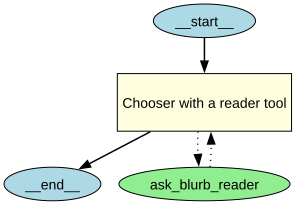

In [15]:
from agents.extensions.visualization import draw_graph

chooser_with_tool = Agent(
    name="Chooser with a reader tool",
    instructions=chooser.instructions + " Ask the blurb reader about each book.",
    model=MODEL,
    tools=[reader.as_tool(tool_name="ask_blurb_reader",
                          tool_description="Ask the blurb reader whether one book on the shortlist fits the club.")],
    model_settings=SETTINGS,
)

draw_graph(chooser_with_tool)

One agent box and one tool, `ask_blurb_reader`, with dotted arrows both ways: the chooser asks, and the answer comes
back to it. To the chooser the reader is just a tool. The reader's own `read_blurb` is not in the drawing.

### A handoff from a front desk to the reader

`handoffs=[reader]` lets an agent pass the conversation to the reader. The reader then takes over and writes the reply
itself.

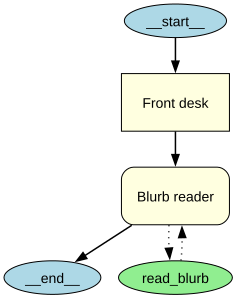

In [16]:
front_desk = Agent(
    name="Front desk",
    instructions="You answer the book club's messages. Hand questions about a book's blurb to the Blurb reader.",
    model=MODEL,
    handoffs=[reader],
    model_settings=SETTINGS,
)

draw_graph(front_desk)

The reader is now a box of its own, with its own tool. The arrow from `Front desk` to it is solid and goes one way,
and the arrow to `__end__` leaves from the reader: once the conversation is handed off, the reader answers, and the
front desk does not get it back.

### Our code connects the readers and the chooser

The design of Part C, drawn the same way:

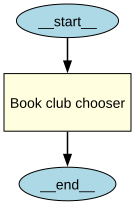

In [17]:
draw_graph(chooser)

One agent, no tools, nothing else. The drawing does not show the five readers, because no agent object points to
them: the connection is the Python in Part C, which ran the readers first and put their lines in the chooser's input.

| How the two agents are connected | Who decides what runs next | Does control come back? | What the agent that answers reads |
|---|---|---|---|
| the reader **as a tool** of the chooser | the chooser's model, on every turn | yes, after each call | its own tool calls and the lines the reader returns |
| a **handoff** to the reader | the front desk's model, once | no, the reader takes over | the conversation so far, plus every blurb the reader opens |
| **our code** runs the readers, then the chooser | our code | nothing to come back to: our code goes on | only what our code puts in its input |

Lab 07's second notebook runs the first two on the Chinook support desk, with a question in two parts. When a main
agent calls two specialist agents (agents that each have their own tools) as tools, the answer has both parts. When
the main agent hands the question off to one specialist, the answer misses the part that specialist has no tool to
look up. The Challenge runs the first way here.

**Checkpoint D.** Three drawings: `Chooser with a reader tool` with `ask_blurb_reader` as a tool and dotted arrows
both ways; `Front desk` with a one-way arrow to `Blurb reader`, which has its own `read_blurb`; the chooser alone, with
nothing to show that our code ran the readers first.

---

## Part E: Answer the club's chat commands in code, with no model call

Not every request needs a model. The club's group chat has a helper, and some messages start with a **command**, a
label that already says what to do: `/next` asks when the next meeting is, and `/pages Title` asks how long a book is.
For those the steps are fixed and written in our code, so it can answer with no tokens, no waiting and the same answer every time. Any
other message goes to the agent from Part B. A design where code handles the requests it can name and an agent
handles the rest is called a **hybrid**.

In [18]:
import re


def next_meeting(argument):
    return "Next meeting: Thursday 4 December, 7 pm, in the library's reading room."


def page_count(title):
    if title not in BOOKS:
        return f"There is no book called {title!r} on the shortlist."
    pages = re.search(r"(\d+) pages", BOOKS[title]).group(1)
    return f"{title}: {pages} pages"


COMMANDS = {"/next": next_meeting, "/pages": page_count}


async def answer(message):
    """Return the reply and the number of model requests it took."""
    command, _, argument = message.partition(" ")
    if command in COMMANDS:                       # a command: our code answers
        return COMMANDS[command](argument), 0
    run = await Runner.run(helper, message)       # anything else goes to the agent
    return run.final_output, run.context_wrapper.usage.requests

How `answer` works, step by step:

1. `message.partition(" ")` splits the message at its first space into three parts: the word before it, the space,
   and the rest. For `/pages The Night Ferry` the command is `/pages` and the argument `The Night Ferry`.
2. If the command is a key of `COMMANDS`, our code calls that function with the argument and reports 0 model
   requests.
3. Otherwise the whole message goes to `helper`, the agent of Part B, and we report the requests its run made.

`page_count` reads the number in front of "pages" in the blurb's first line with a regular expression: `(\d+)` is one
or more digits, and `.group(1)` returns them.

In [19]:
for message in ["/next", "/pages The Night Ferry", "Is The Night Ferry too scary for my 15-year-old?"]:
    reply, requests = await answer(message)
    print(f"{message}\n  -> {reply}\n  model requests: {requests}\n")

/next
  -> Next meeting: Thursday 4 December, 7 pm, in the library's reading room.
  model requests: 0

/pages The Night Ferry
  -> The Night Ferry: 412 pages
  model requests: 0



Is The Night Ferry too scary for my 15-year-old?
  -> It’s described as suitable for older teens, with only mild violence, so it doesn’t sound especially graphic or too scary for a 15-year-old—though it is a suspenseful, slow-building mystery. It’s 412 pages with long chapters, so it may not fit your club’s page limit or bus-reading preference.
  model requests: 2



Our code answered the two commands: the meeting from `next_meeting`, and 412 pages from the blurb's first line, with 0 model requests each. The question about *The Night Ferry* has no command, so it went to the agent, which read the blurb and answered from its last line (mild violence, suitable for older teenagers), in 2 requests.

**Important:** the code goes by the label alone and reads nothing else. A command typed with the wrong label gets the
wrong steps, with no error and no model to notice. Notebook 2 shows this on a support desk's form.

**Checkpoint E.** `/next` and `/pages The Night Ferry` (412 pages) answered with 0 model requests; the free-text
question about *The Night Ferry* answered by the agent, which reads the blurb's line on mild violence (2
requests in our run).

---

## What you can do now

- Read what an agent read before it answered, from `raw_responses` and `to_input_list()`, and name the answering
  request (Part B).
- Start several agents at the same time from your own code with `asyncio.gather`, and pass their one-line results to
  an agent that writes the answer (Part C).
- Compare two designs on one question by the answer, the requests, the tokens in total and the answering request's
  input (Part C).
- Connect two agents as a tool, with a handoff or in your own code, and say from the drawing who decides the next step
  (Part D).
- Answer a labelled request in code with no model call, and send everything else to an agent (Part E).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH` | `draw_graph` needs the Graphviz program, not only the Python package | install Graphviz (`sudo apt install -y graphviz` on Ubuntu, `brew install graphviz` on a Mac); every other cell works without it |
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, write `await Runner.run(...)` |
| `TypeError: An asyncio.Future, a coroutine or an awaitable is required` | the list given to `gather` held finished results, because each `Runner.run(...)` inside it was awaited | build the list without `await`, and await only the `gather` |

## Challenge

1. **Let a model split the work.** Run `chooser_with_tool` from Part D on `QUESTION`, and print its answer, the
   requests, and what the chooser asked for on each of its own requests (`raw_responses`, as in Part B). Then print
   its answering request's input tokens. Expected: on its first request the chooser asks for `ask_blurb_reader` five
   times in one reply, the SDK runs the five readers at the same time, and the run takes 12 requests (1 + 5 × 2 + 1).
   The chooser's answering request reads more than Part C's chooser and less than half of Part B's agent (ours: 861
   tokens), because it also carries its own five tool calls and their inputs.
2. **Ask what the notes leave out.** Ask Part C's chooser *Which of these books has recipes in it?*, with the same
   five notes after the question, and ask Part B's `helper` the same question followed by the five titles. Expected:
   the chooser says the notes do not say, because no reader wrote about recipes; the helper reads the blurbs again
   and names *Salt and Saffron*, which has a recipe at the end of each chapter (it may add *The Lighthouse Bakery*,
   whose story has a notebook of recipes).

The worked solution, run with its outputs, is in `solved/18a_meet_agent_designs_solution.ipynb`.

## Going further

- **The designs over several runs.** `18_extra_measure_the_designs.ipynb` in this folder runs one agent and the five
  readers five times each, on this question and on notebook 2's, and puts every run in one table. It also shows an
  A2A agent card: how an agent that another team runs describes itself to other agents.
- **`async` and `await` from the beginning.** Lab 07 has an extra notebook, `07_extra_async_await.ipynb`, that goes
  step by step from a plain function to two model calls run at the same time with `asyncio.gather`.

## Resources

- [OpenAI Agents SDK: agent orchestration](https://openai.github.io/openai-agents-python/multi_agent/): orchestration
  by a model and by code, agents as tools, handoffs, and agents run in parallel with `asyncio.gather`
- [OpenAI Agents SDK: tools](https://openai.github.io/openai-agents-python/tools/): `function_tool` and
  `Agent.as_tool`
- [OpenAI Agents SDK: handoffs](https://openai.github.io/openai-agents-python/handoffs/)
- [OpenAI Agents SDK: results](https://openai.github.io/openai-agents-python/results/): `final_output`,
  `raw_responses` and `to_input_list()`
- [OpenAI Agents SDK: tracing](https://openai.github.io/openai-agents-python/tracing/): traces, spans and `trace()`
- [OpenAI Agents SDK: agent visualization](https://openai.github.io/openai-agents-python/visualization/):
  `draw_graph`
- [Python `asyncio`: coroutines and tasks](https://docs.python.org/3/library/asyncio-task.html): `await` and `gather`

Next: [notebook 2, agent designs at the Chinook support desk](18b_agent_designs_at_the_desk.ipynb).